In [2]:
import matplotlib.pyplot as plt
import requests
import pandas as pd
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# A session that automatically retries when ChEMBL's server has a hiccup (error 500 etc.),
# waiting a little longer before each new attempt
session = requests.Session()
retries = Retry(total=8, backoff_factor=1, status_forcelist=[500, 502, 503, 504])
session.mount("https://", HTTPAdapter(max_retries=retries))


def get_activities(target_id):
    url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"
    params = {"target_chembl_id": target_id, "pchembl_value__isnull": "false", "limit": 200}
    rows = []
    while url:
        r = session.get(url, params=params, timeout=90)
        r.raise_for_status()
        page = r.json()
        rows += page["activities"]
        # ChEMBL sends results in pages; follow the link to the next page
        nxt = page["page_meta"]["next"]
        url = "https://www.ebi.ac.uk" + nxt if nxt else None
        params = None  # the next-page link already includes the filters
        print(f"Downloaded {len(rows)} of {page['page_meta']['total_count']} records")
    return pd.DataFrame(rows)




In [20]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent        # notebooks/ -> project root
DATA_DIR = PROJECT_ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)
raw_path = DATA_DIR / "notum_raw.csv"

if raw_path.exists():
    # Already downloaded: load the saved copy, no ChEMBL request
    df = pd.read_csv(raw_path)
    print(f"Loaded {len(df)} rows from {raw_path.relative_to(PROJECT_ROOT)}")
else:
    # First run only: download from ChEMBL and save
    df = get_activities("CHEMBL3714531")
    df.to_csv(raw_path, index=False)
    print(f"Downloaded and saved {len(df)} rows to {raw_path.relative_to(PROJECT_ROOT)}")

df.columns

Loaded 783 rows from data\notum_raw.csv


Index(['action_type', 'activity_comment', 'activity_id', 'activity_properties',
       'assay_chembl_id', 'assay_description', 'assay_type',
       'assay_variant_accession', 'assay_variant_mutation', 'bao_endpoint',
       'bao_format', 'bao_label', 'canonical_smiles', 'data_validity_comment',
       'data_validity_description', 'document_chembl_id', 'document_journal',
       'document_year', 'ligand_efficiency', 'modality', 'molecule_chembl_id',
       'molecule_pref_name', 'parent_molecule_chembl_id', 'pchembl_value',
       'potential_duplicate', 'qudt_units', 'record_id', 'relation', 'src_id',
       'standard_flag', 'standard_relation', 'standard_text_value',
       'standard_type', 'standard_units', 'standard_upper_value',
       'standard_value', 'target_chembl_id', 'target_organism',
       'target_pref_name', 'target_tax_id', 'text_value', 'toid', 'type',
       'units', 'uo_units', 'upper_value', 'value'],
      dtype='str')

In [18]:
## Cleaning data cell

from rdkit import Chem

print(df.shape)

# Filtering for relevant columns
df_sel = df[['molecule_chembl_id', 'molecule_pref_name', 'canonical_smiles', 'standard_type',
        'standard_relation', 'pchembl_value', 'assay_chembl_id', 'assay_type',
        'document_chembl_id', 'document_year']].copy()
print(df_sel.shape)

# Only utilising IC50 scores
df_filtered = df_sel.loc[df_sel['standard_type'] == 'IC50'].copy()
print(df_filtered.shape)

# Only standard_relation values with exact figures, so we do not train the model on a range, to give better predictions
df_filtered = df_filtered.loc[df_filtered['standard_relation'] == '='].copy()
print(df_filtered.shape)

# Filtering by B assay type (binding assays) which are the only relevant type of assay
df_filtered = df_filtered.loc[df_filtered['assay_type'] == 'B'].copy()
print(df_filtered.shape)

# Removing entries missing pchembl_values and SMILES
df_filtered = df_filtered.dropna(subset=['canonical_smiles', 'pchembl_value'])
print(df_filtered.shape)

# Function to convert any non-canonical smiles -> canonical smiles
def SMILES_To_CSMILES(DataFrame: pd.DataFrame, column: str, series_name: str):
    '''Function that takes in a pd.DataFrame, a column string name and an output series name
     converts anything in SMILES format into canonical SMILES format'''

    # Initialising a list to store SMILES -> Canonical SMILES
    tmp_smiles = []

    # Looping over each row in df[column]
    for i, smiles in enumerate(DataFrame[column]):
        # Converting to mol object
        mol = Chem.MolFromSmiles(smiles)
        try:
            # Converts to canonical SMILES
            tmp_smiles.append(Chem.MolToSmiles(mol))
        except Exception as e:
            # If there are issues, appends 'Error' to keep same dimensions and prints an error message with the row position where function could not append correctly and prints the e message
            tmp_smiles.append("Error")
            print(f'The following problem was found when generating SMILES for molecule:{i} : {e}')

    # Initialises the output series as the values from temp list and set the index to match the original and sets the name to whatever was passed through the function
    canonical_series = pd.Series(tmp_smiles, index= DataFrame.index, name = series_name)
    return canonical_series

# Checking result
df_conversion = SMILES_To_CSMILES(df_filtered, 'canonical_smiles', 'Canonical')
print(df_conversion.shape)

# Replacing non-canonical with the canonical SMILES
df_filtered['canonical_smiles'] = df_conversion
print(df_filtered.shape)

(783, 47)
(783, 10)
(670, 10)
(670, 10)
(670, 10)
(670, 10)
(670,)
(670, 10)


In [21]:
## Removing duplicate molecules
# Utilising median values for pchembl_value, so that maximum or first value cause our model to over/underestimate its predictions
# Removing redundant features (assay_id, chembl_id, pref_name,
# Model will train on canonical SMILES (.groupby)
# Keeping year information to have a time-based split
#

df_clean = (df_filtered
            .groupby('canonical_smiles', as_index=False)
            .agg(molecule_chembl_id=('molecule_chembl_id', 'first'),
                 pchembl_value=('pchembl_value', 'median'),
                 n_measurements=('pchembl_value', 'size'),
                 first_year=('document_year', 'min'),))
print(df_clean.shape)



(571, 5)


In [22]:
## Saving final clean csv file

clean_path = DATA_DIR / "notum_clean.csv"
df_clean.to_csv(clean_path, index=False)
print(f"Saved {len(df_clean)} rows to {clean_path.relative_to(PROJECT_ROOT)}")

Saved 571 rows to data\notum_clean.csv


(array([21., 57., 72., 86., 94., 71., 73., 62., 28.,  7.]),
 array([3.51 , 4.099, 4.688, 5.277, 5.866, 6.455, 7.044, 7.633, 8.222,
        8.811, 9.4  ]),
 <BarContainer object of 10 artists>)

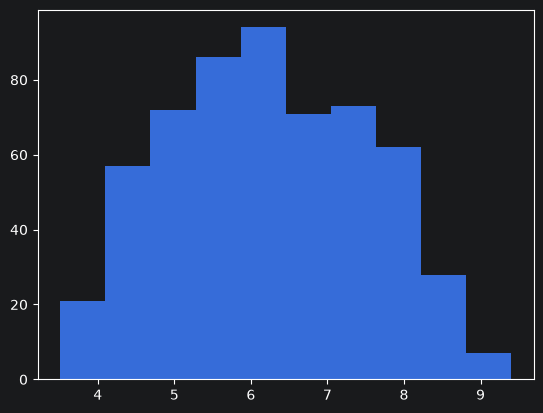

In [24]:
# Visualising data to identify clear outliers / molecules that do not actually bind (low pchembl_value)

display(plt.hist(df_clean['pchembl_value']))